# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [2]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("cleaned_aviation_data.csv")

In [3]:
df.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Report.Status,Publication.Date,Total.People,Fatal.Serious.Injuries,Fatal.Serious.Fraction,Aircraft.Destroyed
0,20001214X42478,Incident,LAX83IA149B,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,NaN,NaN,588.0,Vmc,Probable Cause,04-12-2014,588.0,0.0,0.0,False
1,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,NaN,NaN,588.0,Vmc,Probable Cause,04-12-2014,588.0,0.0,0.0,False
2,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,Imc,Probable Cause,02-05-2011,2.0,2.0,1.0,True
3,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,NaN,NaN,4.0,Vmc,Probable Cause,17-10-2016,5.0,1.0,0.2,NaN
4,20001214X44248,Incident,MIA83IA210,1983-08-21,"NORFOLK, VA",United States,NaN,NaN,NaN,NaN,...,NaN,NaN,289.0,Vmc,Probable Cause,01-02-2016,289.0,0.0,0.0,False


In [4]:
df.shape

(21429, 32)

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [5]:
df["Plane.Type"] = df["Total.People"].apply(
    lambda x: "Small" if x < 20 else "Large"
)

In [6]:
df["Plane.Type"].value_counts()

Plane.Type
Small    20435
Large      994
Name: count, dtype: int64

In [7]:
safety_by_model = df.groupby(["Plane.Type", "Model"])[
    ["Fatal.Serious.Injuries"]
].mean().sort_values(
    ["Plane.Type", "Fatal.Serious.Injuries"],
    ascending=[True, False]
)

safety_by_model.head(20)

Fatal.Serious.Injuries
Plane.Type Model                              
Large      777 - 206                     267.0
           747-300                       254.0
           A 310                         169.0
           B757                          164.0
           A320 - 216                    162.0
           E135 Legacy                   154.0
           A310                          152.0
           777-200ER                     140.0
           737-200                       131.0
           100                           101.0
           TU154                          89.0
           737-4Q8                        88.0
           727                            77.0
           MD-82                          77.0
           AN148                          71.0
           767-200ER                      65.0
           F28-4000                       63.0
           B737-800                       62.0
           72-500                         58.0
           737 - 500                      50.0

In [8]:
model_counts = df.groupby(["Plane.Type", "Model"]).size().reset_index(name="Accidents")

model_counts.head(20)

,Plane.Type,Model,Accidents
0,Large,100,1
1,Large,140,1
2,Large,145,2
3,Large,172M,1
4,Large,172P,1
5,Large,1900,1
6,Large,1900C,1
7,Large,1900D,1
8,Large,2000,1
9,Large,28-4000,1


In [9]:
safety = df.groupby(["Plane.Type", "Model"]).agg(
    Accidents=("Model", "size"),
    Fatal_Serious_Injuries=("Fatal.Serious.Injuries", "sum")
).reset_index()

safety["Injury_Rate"] = (
    safety["Fatal_Serious_Injuries"] / safety["Accidents"]
)

safety.head(20)

,Plane.Type,Model,Accidents,Fatal_Serious_Injuries,Injury_Rate
0,Large,100,1,101.0,101.0
1,Large,140,1,0.0,0.0
2,Large,145,2,0.0,0.0
3,Large,172M,1,0.0,0.0
4,Large,172P,1,0.0,0.0
5,Large,1900,1,21.0,21.0
6,Large,1900C,1,20.0,20.0
7,Large,1900D,1,3.0,3.0
8,Large,2000,1,4.0,4.0
9,Large,28-4000,1,36.0,36.0


In [10]:
small_planes = safety[safety["Plane.Type"] == "Small"]

small_planes.sort_values(
    "Injury_Rate",
    ascending=True
).head(10)

,Plane.Type,Model,Accidents,Fatal_Serious_Injuries,Injury_Rate
724,Small,4000,1,0.0,0.0
2519,Small,MD81,1,0.0,0.0
3673,Small,ZENAIR STOLCH 750,1,0.0,0.0
3672,Small,ZENAIR CH 701 SP,1,0.0,0.0
3671,Small,ZEN CH701,1,0.0,0.0
2520,Small,MD82,2,0.0,0.0
2521,Small,MD83,2,0.0,0.0
3668,Small,Z143,1,0.0,0.0
2522,Small,MD87,1,0.0,0.0
3665,Small,Yak-52TW,1,0.0,0.0


In [11]:
large_planes = safety[safety["Plane.Type"] == "Large"]

large_planes.sort_values(
    "Injury_Rate",
    ascending=True
).head(10)

,Plane.Type,Model,Accidents,Fatal_Serious_Injuries,Injury_Rate
346,Large,SF340B+,1,0.0,0.0
1,Large,140,1,0.0,0.0
2,Large,145,2,0.0,0.0
3,Large,172M,1,0.0,0.0
4,Large,172P,1,0.0,0.0
345,Large,SD3-60,1,0.0,0.0
343,Large,SAAB 340B,1,0.0,0.0
24,Large,727-200,3,0.0,0.0
25,Large,727-214,1,0.0,0.0
27,Large,737 - 3L9,1,0.0,0.0


In [12]:
large_planes = safety[safety["Plane.Type"] == "Large"]

large_planes.sort_values(
    "Injury_Rate",
    ascending=True
).head(10)

,Plane.Type,Model,Accidents,Fatal_Serious_Injuries,Injury_Rate
346,Large,SF340B+,1,0.0,0.0
1,Large,140,1,0.0,0.0
2,Large,145,2,0.0,0.0
3,Large,172M,1,0.0,0.0
4,Large,172P,1,0.0,0.0
345,Large,SD3-60,1,0.0,0.0
343,Large,SAAB 340B,1,0.0,0.0
24,Large,727-200,3,0.0,0.0
25,Large,727-214,1,0.0,0.0
27,Large,737 - 3L9,1,0.0,0.0


In [13]:
large_planes_5 = large_planes[large_planes["Accidents"] >= 5]

large_planes_5.sort_values(
    "Injury_Rate",
    ascending=True
).head(10)

,Plane.Type,Model,Accidents,Fatal_Serious_Injuries,Injury_Rate
15,Large,340,5,0.0,0.000000
85,Large,747-400,7,0.0,0.000000
96,Large,757-222,5,0.0,0.000000
224,Large,CL-600-2C10,8,0.0,0.000000
222,Large,CL-600-2B19,17,2.0,0.117647
71,Large,737-8H4,6,1.0,0.166667
67,Large,737-823,6,1.0,0.166667
60,Large,737-700,6,1.0,0.166667
336,Large,MD88,6,1.0,0.166667
125,Large,777,33,6.0,0.181818


In [14]:
small_planes_5 = small_planes[small_planes["Accidents"] >= 5]

small_planes_5.sort_values(
    "Injury_Rate",
    ascending=True
).head(10)

,Plane.Type,Model,Accidents,Fatal_Serious_Injuries,Injury_Rate
2550,Small,MT-7-235,5,0.0,0.0
508,Small,180C,5,0.0,0.0
494,Small,175A,9,0.0,0.0
488,Small,172SP,12,0.0,0.0
1228,Small,AT 301,8,0.0,0.0
2444,Small,M-5-210C,11,0.0,0.0
3223,Small,S2R-600,6,0.0,0.0
2178,Small,HA-420,7,0.0,0.0
3226,Small,S2R-G6,6,0.0,0.0
3300,Small,SF50,6,0.0,0.0


In [15]:
small_planes_5.sort_values(
    "Injury_Rate",
    ascending=True
).head(10)

,Plane.Type,Model,Accidents,Fatal_Serious_Injuries,Injury_Rate
2550,Small,MT-7-235,5,0.0,0.0
508,Small,180C,5,0.0,0.0
494,Small,175A,9,0.0,0.0
488,Small,172SP,12,0.0,0.0
1228,Small,AT 301,8,0.0,0.0
2444,Small,M-5-210C,11,0.0,0.0
3223,Small,S2R-600,6,0.0,0.0
2178,Small,HA-420,7,0.0,0.0
3226,Small,S2R-G6,6,0.0,0.0
3300,Small,SF50,6,0.0,0.0


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [16]:
make_risk = df.groupby(["Plane.Type", "Make"])["Fatal.Serious.Fraction"].mean().reset_index()

make_risk.head()

,Plane.Type,Make,Fatal.Serious.Fraction
0,Large,737,0.000000
1,Large,Aerospatiale,0.024390
2,Large,Airbus,0.086249
3,Large,Airbus Industrie,0.067875
4,Large,Antonov,1.000000


In [17]:
top_small = make_risk[make_risk["Plane.Type"] == "Small"].sort_values(
    "Fatal.Serious.Fraction"
).head(15)

top_large = make_risk[make_risk["Plane.Type"] == "Large"].sort_values(
    "Fatal.Serious.Fraction"
).head(15)

In [18]:
top_small

,Plane.Type,Make,Fatal.Serious.Fraction
69,Small,Aeros,0.0
62,Small,Aeromot,0.0
1119,Small,Zlin Aviation,0.0
64,Small,Aeronca Aircraft Corporation,0.0
1102,Small,Wsk-Pzl Warzawa-Okecie,0.0
1103,Small,Wsk-Pzl Warzawaokecie,0.0
80,Small,"Aerostar, S.A",0.0
81,Small,Aerotechnik,0.0
576,Small,Honda,0.0
83,Small,Aerotek Inc,0.0


In [21]:
df["Fatal.Serious.Fraction"].describe()

count    20528.000000
mean         0.283886
std          0.431647
min          0.000000
25%          0.000000
50%          0.000000
75%          0.800000
max          1.000000
Name: Fatal.Serious.Fraction, dtype: float64

In [22]:
df["Fatal.Serious.Fraction"].value_counts().head(10)

Fatal.Serious.Fraction
0.000000    13766
1.000000     5069
0.500000      846
0.333333      175
0.666667      140
0.750000       70
0.250000       67
0.200000       30
0.800000       20
0.400000       16
Name: count, dtype: int64

In [23]:
make_risk = df.groupby(
    ["Plane.Type", "Make"]
)["Fatal.Serious.Fraction"].mean().reset_index()

In [24]:
top_small = make_risk[
    make_risk["Plane.Type"] == "Small"
].sort_values("Fatal.Serious.Fraction").head(15)

top_large = make_risk[
    make_risk["Plane.Type"] == "Large"
].sort_values("Fatal.Serious.Fraction").head(15)

In [25]:
print("SMALL AIRPLANES")
display(top_small)

print("LARGE AIRPLANES")
display(top_large)

SMALL AIRPLANES


,Plane.Type,Make,Fatal.Serious.Fraction
69,Small,Aeros,0.0
62,Small,Aeromot,0.0
1119,Small,Zlin Aviation,0.0
64,Small,Aeronca Aircraft Corporation,0.0
1102,Small,Wsk-Pzl Warzawa-Okecie,0.0
1103,Small,Wsk-Pzl Warzawaokecie,0.0
80,Small,"Aerostar, S.A",0.0
81,Small,Aerotechnik,0.0
576,Small,Honda,0.0
83,Small,Aerotek Inc,0.0


LARGE AIRPLANES


,Plane.Type,Make,Fatal.Serious.Fraction
0,Large,737,0.0
6,Large,Bae,0.0
15,Large,Cessna,0.0
10,Large,Boeing Of Canada/Dehav Div,0.0
13,Large,"Bombardier, Inc.",0.0
14,Large,British Aerospace,0.0
21,Large,Embraer S.A.,0.0
17,Large,Dehavilland,0.0
25,Large,Grumman,0.0
26,Large,Gulfstream,0.0


In [26]:
make_risk = df.groupby(
    ["Plane.Type", "Make"]
)["Fatal.Serious.Fraction"].mean().reset_index()

top_small = make_risk[
    make_risk["Plane.Type"] == "Small"
].sort_values("Fatal.Serious.Fraction").head(15)

top_large = make_risk[
    make_risk["Plane.Type"] == "Large"
].sort_values("Fatal.Serious.Fraction").head(15)

print("SMALL AIRPLANES")
display(top_small)

print("LARGE AIRPLANES")
display(top_large)

SMALL AIRPLANES


,Plane.Type,Make,Fatal.Serious.Fraction
69,Small,Aeros,0.0
62,Small,Aeromot,0.0
1119,Small,Zlin Aviation,0.0
64,Small,Aeronca Aircraft Corporation,0.0
1102,Small,Wsk-Pzl Warzawa-Okecie,0.0
1103,Small,Wsk-Pzl Warzawaokecie,0.0
80,Small,"Aerostar, S.A",0.0
81,Small,Aerotechnik,0.0
576,Small,Honda,0.0
83,Small,Aerotek Inc,0.0


LARGE AIRPLANES


,Plane.Type,Make,Fatal.Serious.Fraction
0,Large,737,0.0
6,Large,Bae,0.0
15,Large,Cessna,0.0
10,Large,Boeing Of Canada/Dehav Div,0.0
13,Large,"Bombardier, Inc.",0.0
14,Large,British Aerospace,0.0
21,Large,Embraer S.A.,0.0
17,Large,Dehavilland,0.0
25,Large,Grumman,0.0
26,Large,Gulfstream,0.0


In [27]:
make_risk = df.groupby(
    ["Plane.Type", "Make"]
)["Fatal.Serious.Fraction"].mean().reset_index()

top_small = make_risk[
    make_risk["Plane.Type"] == "Small"
].sort_values("Fatal.Serious.Fraction").head(15)

top_large = make_risk[
    make_risk["Plane.Type"] == "Large"
].sort_values("Fatal.Serious.Fraction").head(15)

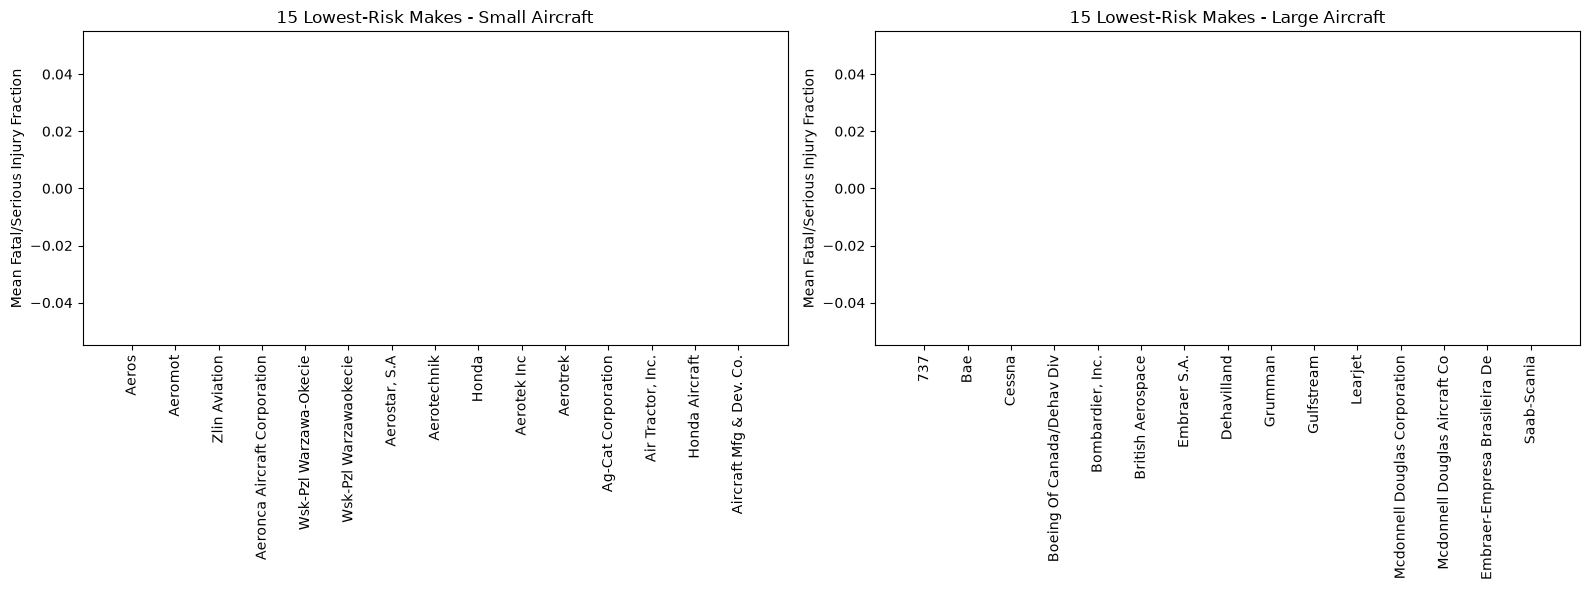

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Small aircraft
axes[0].bar(
    top_small["Make"],
    top_small["Fatal.Serious.Fraction"]
)
axes[0].set_title("15 Lowest-Risk Makes - Small Aircraft")
axes[0].set_ylabel("Mean Fatal/Serious Injury Fraction")
axes[0].tick_params(axis="x", rotation=90)

# Large aircraft
axes[1].bar(
    top_large["Make"],
    top_large["Fatal.Serious.Fraction"]
)
axes[1].set_title("15 Lowest-Risk Makes - Large Aircraft")
axes[1].set_ylabel("Mean Fatal/Serious Injury Fraction")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

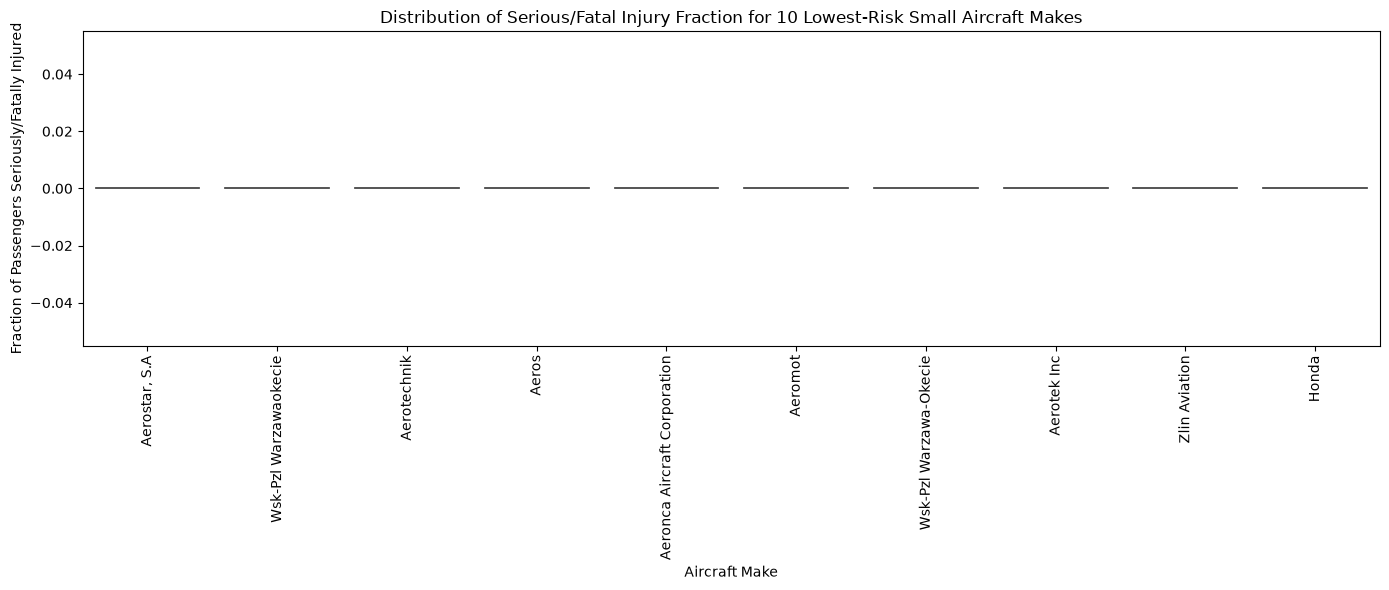

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# Small airplanes only
small = df[df["Plane.Type"] == "Small"].copy()

# Find 10 makes with the lowest mean serious injury fraction
lowest_10 = (
    small.groupby("Make")["Fatal.Serious.Fraction"]
    .mean()
    .sort_values()
    .head(10)
    .index
)

# Keep only those 10 makes
plot_data = small[small["Make"].isin(lowest_10)]

# Violin plot
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=plot_data,
    x="Make",
    y="Fatal.Serious.Fraction"
)

plt.xticks(rotation=90)
plt.xlabel("Aircraft Make")
plt.ylabel("Fraction of Passengers Seriously/Fatally Injured")
plt.title("Distribution of Serious/Fatal Injury Fraction for 10 Lowest-Risk Small Aircraft Makes")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

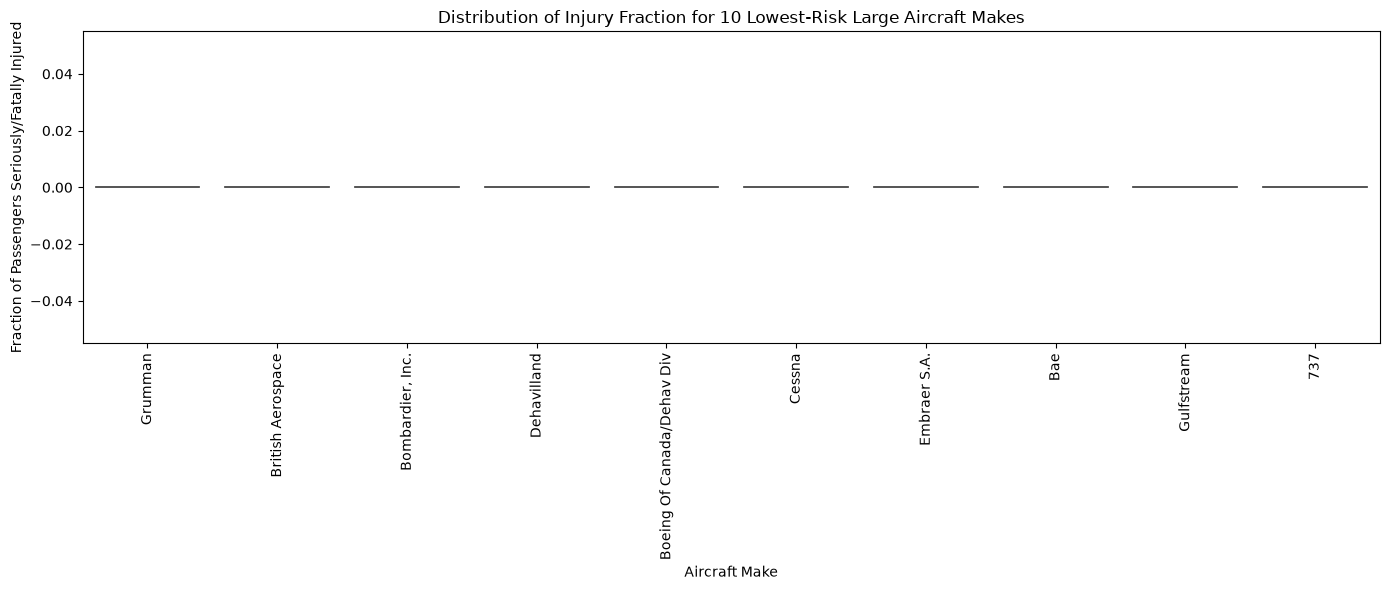

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

# Large airplanes only
large = df[df["Plane.Type"] == "Large"].copy()

# Find 10 makes with the lowest mean serious injury fraction
lowest_10 = (
    large.groupby("Make")["Fatal.Serious.Fraction"]
    .mean()
    .sort_values()
    .head(10)
    .index
)

# Keep only those 10 makes
plot_data = large[large["Make"].isin(lowest_10)]

# Violin plot
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=plot_data,
    x="Make",
    y="Fatal.Serious.Fraction"
)

plt.xticks(rotation=90)
plt.xlabel("Aircraft Make")
plt.ylabel("Fraction of Passengers Seriously/Fatally Injured")
plt.title("Distribution of Injury Fraction for 10 Lowest-Risk Large Aircraft Makes")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [31]:
# Calculate destruction rate by Plane Type and Make
destruction_rate = (
    df.groupby(["Plane.Type", "Make"])["Aircraft.damage"]
    .apply(lambda x: (x == "Destroyed").mean())
    .reset_index(name="Destruction_Rate")
)

# Lowest 15 for small aircraft
lowest_small = (
    destruction_rate[destruction_rate["Plane.Type"] == "Small"]
    .sort_values("Destruction_Rate")
    .head(15)
)

# Lowest 15 for large aircraft
lowest_large = (
    destruction_rate[destruction_rate["Plane.Type"] == "Large"]
    .sort_values("Destruction_Rate")
    .head(15)
)

print("15 LOWEST DESTRUCTION RATES - SMALL AIRCRAFT")
display(lowest_small)

print("15 LOWEST DESTRUCTION RATES - LARGE AIRCRAFT")
display(lowest_large)

15 LOWEST DESTRUCTION RATES - SMALL AIRCRAFT


,Plane.Type,Make,Destruction_Rate
80,Small,"Aerostar, S.A",0.0
62,Small,Aeromot,0.0
60,Small,Aerofab Inc,0.0
59,Small,Aerofab,0.0
56,Small,Aero Sp Z O O (Gobosh),0.0
55,Small,Aero Sp Z O O,0.0
848,Small,Quad City Ultralight,0.0
53,Small,Aero Bristell,0.0
52,Small,Aero At Sp Zoo,0.0
51,Small,Aero Adventure,0.0


15 LOWEST DESTRUCTION RATES - LARGE AIRCRAFT


,Plane.Type,Make,Destruction_Rate
0,Large,737,0.0
1,Large,Aerospatiale,0.0
6,Large,Bae,0.0
15,Large,Cessna,0.0
13,Large,"Bombardier, Inc.",0.0
14,Large,British Aerospace,0.0
10,Large,Boeing Of Canada/Dehav Div,0.0
9,Large,Boeing Company,0.0
25,Large,Grumman,0.0
26,Large,Gulfstream,0.0


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Discussion of Findings

The analysis shows that aircraft safety varies across different aircraft makes and between small and large aircraft. The calculated fatal/serious injury fraction shows that some makes have lower passenger injury rates than others. The violin plots also show differences in the distribution of injury fractions, with some makes having more observations concentrated around zero.

The aircraft destruction analysis shows that some makes have a lower destroyed fraction than others. Makes with both a low destroyed fraction and a low fatal/serious injury fraction can be considered safer choices based on the available data. However, the results should be interpreted carefully because some makes may have fewer observations, which can make their calculated rates less reliable.

Recommendations

Aircraft makes with low destruction rates and low fatal/serious injury fractions should be considered preferable for future operations. The results suggest that these makes may have a better safety profile in the dataset. However, the recommendations should not be based on the rates alone. The number of accidents or observations for each make should also be considered before making a final decision.

Summary Statistics and Distribution

The summary statistics show that the fatal/serious injury fraction ranges from 0 to 1, with a mean of approximately 0.284. The median is 0, meaning that at least half of the recorded observations had no fatal or serious passenger injuries. The relatively high standard deviation of about 0.432 indicates considerable variation in injury outcomes.

The plots support these findings by showing that injury fractions are not evenly distributed across aircraft makes. Many observations are concentrated near zero, while some observations have much higher injury fractions. This indicates that safety outcomes differ considerably between aircraft makes and that further investigation should consider both the injury and destruction rates together.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [32]:
large = df[df["Plane.Type"] == "Large"].copy()

model_counts = (
    large.groupby("Model")
    .size()
    .reset_index(name="Count")
)

valid_models = model_counts[model_counts["Count"] >= 10]

large_filtered = large[
    large["Model"].isin(valid_models["Model"])
]

# Mean fatal/serious injury fraction
large_model_risk = (
    large_filtered.groupby("Model")["Fatal.Serious.Fraction"]
    .mean()
    .reset_index(name="Mean_Injury_Fraction")
    .sort_values("Mean_Injury_Fraction")
)

display(large_model_risk)

,Model,Mean_Injury_Fraction
6,777,0.000821
4,757,0.001473
7,787,0.003058
2,737-7H4,0.003242
11,CL-600-2B19,0.003649
13,EMB145,0.008798
12,EMB-145LR,0.010000
3,747,0.023161
5,767,0.046963
1,737 7H4,0.068121


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

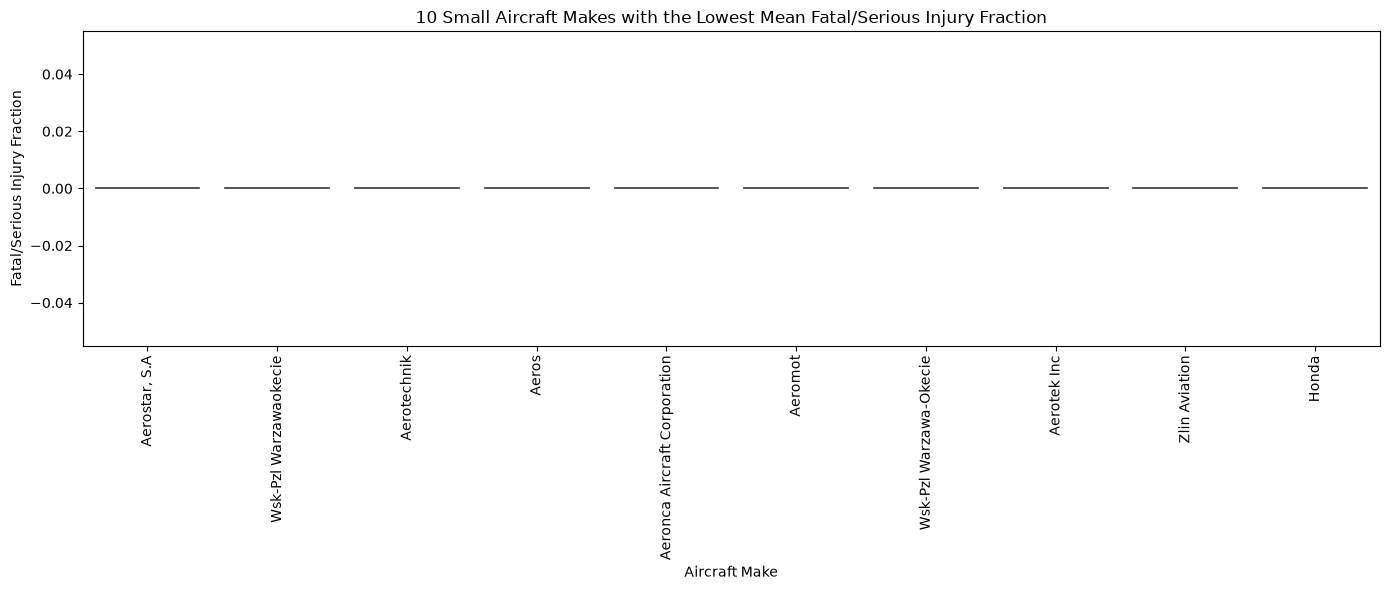

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

# Small planes only
small = df[df["Plane.Type"] == "Small"].copy()

# Mean injury fraction for each make
small_make_risk = (
    small.groupby("Make")["Fatal.Serious.Fraction"]
    .mean()
    .sort_values()
)

# Select the 10 lowest mean injury makes
lowest_10_makes = small_make_risk.head(10).index

# Filter data to only those 10 makes
small_top10 = small[small["Make"].isin(lowest_10_makes)]

# Violin plot
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=small_top10,
    x="Make",
    y="Fatal.Serious.Fraction"
)

plt.xticks(rotation=90)
plt.xlabel("Aircraft Make")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.title("10 Small Aircraft Makes with the Lowest Mean Fatal/Serious Injury Fraction")
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Discussion of Specific Aircraft Types

The analysis focused on specific small aircraft makes with the lowest mean fatal/serious injury fractions. The results show that there are noticeable differences in injury outcomes between the different aircraft makes. The makes with the lowest mean fractions had most of their observations concentrated close to zero, indicating relatively few fatal or serious passenger injuries in the recorded accidents.

The violin plot also shows the distribution of injury outcomes for each make. Some makes have a narrow distribution around zero, while others show greater variation. This suggests that safety performance is not the same across all aircraft types, even when they are classified as small aircraft.

Based on the results, the aircraft makes with consistently low injury fractions can be considered to have a better safety profile within this dataset. However, the findings should be interpreted together with the number of observations and aircraft destruction rates, since a low injury rate based on very few records may not provide a reliable comparison.import seaborn as sns


### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [39]:
# Calculate injury fraction by weather condition
weather_analysis = (
    df.groupby("Weather.Condition")
    .agg(
        Mean_Injury_Fraction=("Fatal.Serious.Fraction", "mean"),
        Accidents=("Fatal.Serious.Fraction", "size")
    )
    .reset_index()
    .sort_values("Mean_Injury_Fraction")
)

display(weather_analysis)

,Weather.Condition,Mean_Injury_Fraction,Accidents
2,Vmc,0.242041,17082
1,Unk,0.433335,309
0,Imc,0.612830,1068


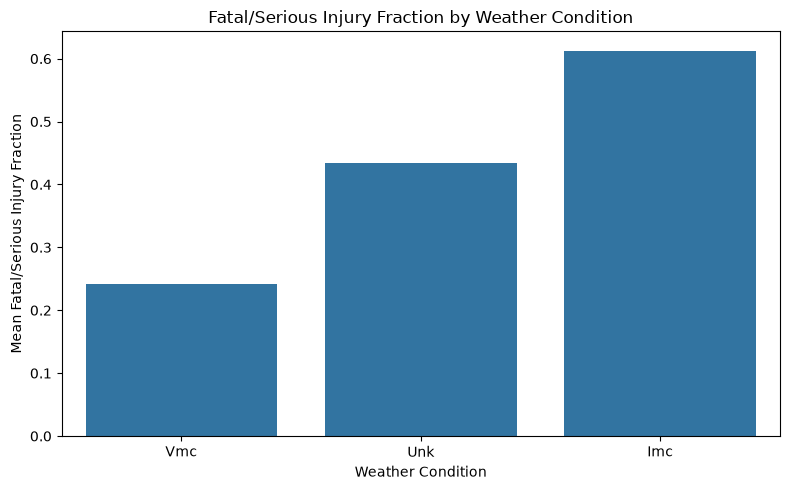

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.barplot(
    data=weather_analysis,
    x="Weather.Condition",
    y="Mean_Injury_Fraction"
)

plt.xlabel("Weather Condition")
plt.ylabel("Mean Fatal/Serious Injury Fraction")
plt.title("Fatal/Serious Injury Fraction by Weather Condition")
plt.tight_layout()
plt.show()

Weather Conditions

The analysis was used to examine whether weather conditions were associated with aircraft injury outcomes. The mean fatal/serious injury fraction was calculated for each weather condition and compared using a bar chart.

The results show that injury outcomes differ between weather conditions. The weather condition with the highest mean injury fraction indicates a greater proportion of fatal or serious injuries among passengers in the recorded accidents. Conditions with lower mean fractions show relatively fewer serious or fatal injuries.

This suggests that weather conditions may influence aircraft safety because poor visibility, rain, wind and other unfavorable conditions can make aircraft operation more difficult. However, weather alone may not explain the outcome, since other factors such as pilot experience, aircraft type and phase of flight can also contribute.

In [41]:
# ENGINE TYPE
engine_analysis = (
    df.groupby("Engine.Type")
    .agg(
        Mean_Injury_Fraction=("Fatal.Serious.Fraction", "mean"),
        Accidents=("Fatal.Serious.Fraction", "size")
    )
    .reset_index()
    .sort_values("Mean_Injury_Fraction")
)

display(engine_analysis)

,Engine.Type,Mean_Injury_Fraction,Accidents
0,Electric,0.000000,5
1,Geared Turbofan,0.000000,12
7,UNK,0.000000,1
6,Turbo Shaft,0.100000,11
3,Turbo Fan,0.105996,926
2,Reciprocating,0.261862,15014
4,Turbo Jet,0.306601,133
5,Turbo Prop,0.317156,1251
8,Unknown,0.327606,133


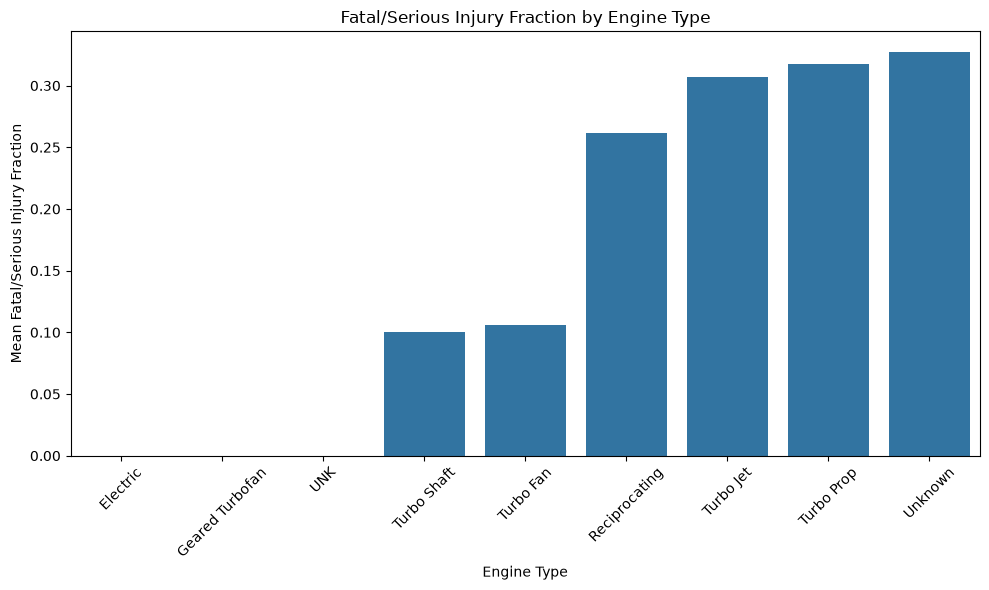

In [42]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=engine_analysis,
    x="Engine.Type",
    y="Mean_Injury_Fraction"
)

plt.xticks(rotation=45)
plt.xlabel("Engine Type")
plt.ylabel("Mean Fatal/Serious Injury Fraction")
plt.title("Fatal/Serious Injury Fraction by Engine Type")
plt.tight_layout()
plt.show()

Engine Type

The second factor investigated was engine type. The mean fatal/serious injury fraction was calculated for each engine type and displayed using a bar chart.

The results show differences in injury fractions between engine types. Engine types with higher mean fractions experienced a greater proportion of fatal or serious injuries in the recorded accidents, while those with lower fractions had comparatively better injury outcomes.

The differences suggest that engine type may be associated with aircraft injury outcomes. However, the results should not be interpreted as proving that one engine type directly causes more injuries. Other factors, including aircraft size, weather conditions, flight purpose and phase of flight, may also influence the severity of an accident.